# Foreign holdings and currency: what the tax man takes, and where

Two things change the tax on a US stock or a US-focused fund that a Canadian stock never shows:

* **Withholding.** The US keeps 15% of the dividend before you see it. What happens to that 15% depends on the **account** (taxable, TFSA, RRSP) and on the **wrapper** (the US stock itself, a US-listed ETF, or a Canadian-listed ETF that holds US stocks).
* **Currency.** The CRA taxes your gain in **Canadian dollars**. A US stock that rises 10% in US dollars can still be a loss for tax purposes if the US dollar fell 15% against the Canadian dollar in the meantime, because the cost base (ACB) is fixed in Canadian dollars on the day you buy.

This notebook builds tiny, hand-made markets so each effect is visible by itself, then points at the bundled S&P 500 sample. It is the deeper companion to `accounts_and_foreign.ipynb`, and it uses no random simulation: every number is arithmetic you could check by hand. Offline, about 30 seconds, writes no files. Not tax advice.

1. **The matrix, visually:** three names, one yield, three accounts.
2. **Wrapper choice:** the same US exposure through a US-listed ETF or a Canadian-listed ETF.
3. **Currency and the cost base:** a gain in US dollars that is a loss in Canadian dollars, and the reverse.
4. **Real data pointer:** the bundled S&P 500 sample in the three accounts, and what your own data would change.
5. **Reading guide:** what this tells you and what it ignores.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Config, Market, ScreenBuilder
from screenlab.backtest import run
from screenlab.data import add_ratios, security_meta
from screenlab.dataset import Dataset
from screenlab.macro import MacroSeries
from screenlab.taxes import CanadianTax, TaxConfig, FX_WARNING
from screenlab.ops.account_compare import treatment, _ledger_capture
from screenlab.research.montecarlo_sp500 import INK, INK2, SURFACE, GRID, _style

%matplotlib inline
plt.rcParams["figure.dpi"] = 80
_style()

MODEL = CanadianTax("AB", other_income=90_000)       # Alberta, $90,000 of other income, the same as the accounts notebook
CAP = 100_000.0                                       # starting money, dollars
ACCOUNTS = ["taxable", "tfsa", "rrsp"]
ACC_NAME = {"taxable": "Taxable", "tfsa": "TFSA", "rrsp": "RRSP"}
ACC_COL = {"taxable": "#0072B2", "tfsa": "#E69F00", "rrsp": "#CC79A7"}     # colour-blind-safe, one hue per account
STATE_COL = {"none": "#E3E2DD", "credited": "#56B4E9", "exempt": "#009E73", "lost": "#D55E00"}
GREY = "#6B6B6B"

try:                                                   # shared tax charts, if the research module has them
    from screenlab.research import tax_plots
except ImportError:
    tax_plots = None
print("shared tax_plots module:", "found" if tax_plots else "not present; this notebook draws its own charts")

shared tax_plots module: found


## The small markets used below

The helper below builds a market of a few names on business days from 2020-01-01. Every name has the same **yield** and the same price growth, so any difference in the results is the tax, nothing else. A name's metadata (`domicile`, `wrapper`, `currency`, `underlying_domicile`) is what the tax stage reads; in your own data it comes from the optional `securities.csv`. Prices here are a total-return index (dividends are paid out in the tax ledger and reinvested). Starting money is $100,000, taxes are paid from outside the account (`pay_from_portfolio=False`) so each year's dollars are exact.

In [2]:
def make_market(spec, years=1, yld=0.04, growth=0.0, picks=None, prices=None):
    """spec: {name: security_meta fields}. Every name is on offer at the start of each year (sector = its own name);
    picks (optional) says which name is in play in which year, as {name: [years]}."""
    dates = pd.bdate_range("2020-01-01", f"{2019 + years}-12-31")
    names = list(spec)
    if prices is None:
        path = (1 + growth) ** ((dates - dates[0]).days.to_numpy() / 365.25)
        prices = pd.DataFrame({t: path for t in names}, index=dates)
    rows = [dict(date=pd.Timestamp(f"{2020 + y}-01-01"), ticker=t, sector=(t if (picks is None or 2020 + y in picks[t]) else "off"),
                 price=10.0, market_cap=1000.0, dividend=10.0 * yld) for y in range(years) for t in names]
    meta = security_meta(names, pd.DataFrame([dict(ticker=t, **v) for t, v in spec.items()]).set_index("ticker"))
    return Market(Dataset.from_frames(add_ratios(pd.DataFrame(rows)), prices, security_meta=meta))

def run_name(market, name, account, macro=None, rrsp_rate=0.30):
    """Hold only `name` for the whole run in `account`; returns the backtest result with the event ledger attached."""
    tc = TaxConfig(model=MODEL, account=account, capital=CAP, rrsp_withdrawal_rate=rrsp_rate, macro=macro, pay_from_portfolio=False)
    screen = ScreenBuilder(f"only_{name}", n=1).where(f"sector == '{name}'").build()
    with _ledger_capture():
        return run(screen, market, Config(rebalance_months=12, cost_bps=0, min_holdings=1, tax=tc), start="2020-01-01")

def withholding_dollars(res, account, rate=0.15):
    """The foreign withholding of a run, by what happened to it, in dollars per year (from the tax stage's own ledger).
    lost: nothing gives it back; credited: the foreign tax credit returns it (taxable); exempt: never withheld (RRSP, US)."""
    _, ev = res.tax.attrs["ledger"]
    ev = ev.reindex(columns=["div_fx", "wh_fx", "wh_fund", "wh_lost"]).fillna(0.0)
    y = ev.groupby(ev.index.year).sum() * CAP
    out = pd.DataFrame(index=y.index, dtype=float)
    out["lost"] = y["wh_fund"] + y["wh_lost"] + (y["wh_fx"] if account == "tfsa" else 0.0)
    out["credited"] = y["wh_fx"] if account == "taxable" else 0.0
    out["exempt"] = y["div_fx"] * rate if account == "rrsp" else 0.0
    return out

## 1. The matrix, visually

Three names, **all with the same 4% yield and no price change over one year**, so each earns the same $4,000 on $100,000 before tax:

* **CA**: a Canadian eligible-dividend stock.
* **US**: a US stock held directly.
* **ETF_CA**: a Canadian-listed ETF (CAD) that holds US stocks.

(The dividend is $3,997 rather than $4,000 because the year has 365 of 365.25 days.) Each is held alone in a taxable account, a TFSA and an RRSP (the RRSP's withdrawal tax is left out here; only the income is compared).

In [3]:
SPEC1 = {"CA": dict(domicile="CA", wrapper="stock", currency="CAD"),
         "US": dict(domicile="US", wrapper="stock", currency="USD"),
         "ETF_CA": dict(domicile="CA", wrapper="etf_ca", underlying_domicile="US", currency="CAD")}
NICE1 = {"CA": "Canadian stock", "US": "US stock (direct)", "ETF_CA": "Canadian-listed ETF\non US stocks"}
m1 = make_market(SPEC1, years=1, yld=0.04)

cells, rows = {}, []
for name in SPEC1:
    for acct in ACCOUNTS:
        r = run_name(m1, name, acct)
        t = r.tax.loc[2020]
        gross = t["dividends_ca"] + t["dividends_foreign"]
        tax_div = t["tax_dividends"] + t["tax_foreign_dividends"]         # tax on the income only (no RRSP withdrawal tax)
        wh = withholding_dollars(r, acct).loc[2020]
        state = "lost" if wh["lost"] > 0 else "credited" if wh["credited"] > 0 else "exempt" if wh["exempt"] > 0 else "none"
        cells[(name, acct)] = (state, wh[state] if state != "none" else 0.0)
        rows.append(dict(name=name, account=acct, gross=gross, tax=tax_div, after_tax=gross - tax_div,
                         withheld_lost=wh["lost"], withheld_credited=wh["credited"], exempt=wh["exempt"]))
inc = pd.DataFrame(rows)
display(inc.assign(name=inc["name"].map(NICE1).str.replace("\n", " "), account=inc["account"].map(ACC_NAME))
        .set_index(["name", "account"]).style.format("{:,.0f}"))

Each row is one name in one account. **gross** is the dividend before anything; **tax** is everything taken on the income (withholding plus Canadian tax); **after_tax** is what is left. The last three columns split the foreign withholding into the part that is gone for good (**lost**), the part the taxable account gets back through the foreign tax credit (**credited**) and the part the RRSP never pays (**exempt**, the treaty).

the ledger of the runs agrees with the documented matrix (docs/TAXES.md): True


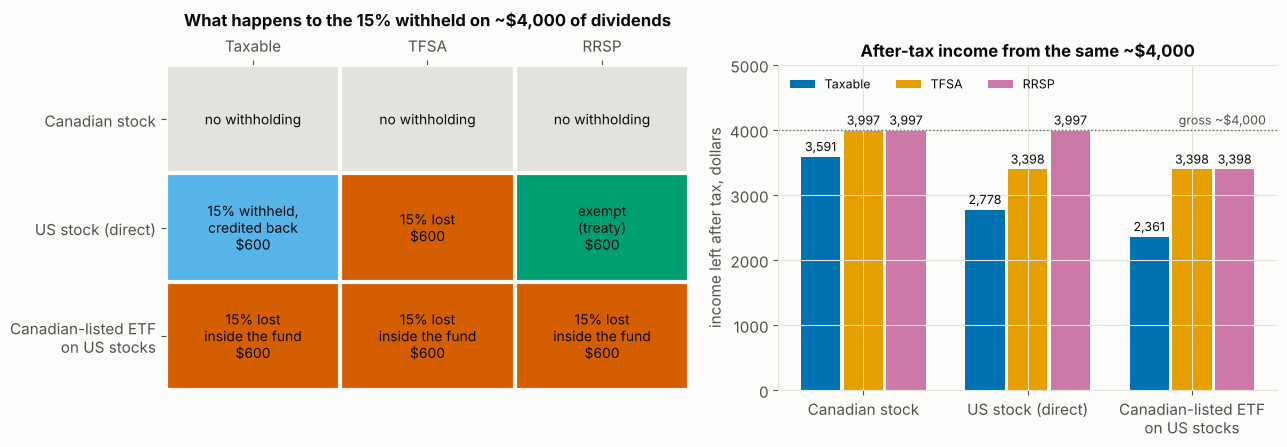

In [4]:
def classify(text):
    return "lost" if "LOST" in text else "credited" if "creditable" in text else "exempt" if "EXEMPT" in text else "none"

KIND = {"CA": ("domestic", "CA"), "US": ("direct", "US"), "ETF_CA": ("fund", "US")}
rate = TaxConfig(model=MODEL).rate_for("US")
doc = {n: {a: classify(treatment(*KIND[n], 0.0 if KIND[n][0] == "domestic" else rate)[a]) for a in ACCOUNTS} for n in SPEC1}
agree = all(doc[n][a] == cells[(n, a)][0] for n in SPEC1 for a in ACCOUNTS)
print("the ledger of the runs agrees with the documented matrix (docs/TAXES.md):", agree)
assert agree

def draw_matrix(ax):
    order = ["none", "credited", "exempt", "lost"]
    z = np.array([[order.index(cells[(n, a)][0]) for a in ACCOUNTS] for n in SPEC1])
    ax.imshow(z, cmap=ListedColormap([STATE_COL[s] for s in order]), vmin=-0.5, vmax=3.5, aspect="auto")
    for i, n in enumerate(SPEC1):
        for j, a in enumerate(ACCOUNTS):
            s, d = cells[(n, a)]
            txt = {"none": "no withholding", "credited": f"{rate:.0%} withheld,\ncredited back", "exempt": "exempt\n(treaty)",
                   "lost": (f"{rate:.0%} lost\ninside the fund" if n == "ETF_CA" else f"{rate:.0%} lost")}[s]
            if s != "none":
                txt += f"\n${d:,.0f}"
            ax.text(j, i, txt, ha="center", va="center", fontsize=10, color=INK)
    ax.set_xticks(range(3), [ACC_NAME[a] for a in ACCOUNTS]); ax.set_yticks(range(3), [NICE1[n] for n in SPEC1])
    ax.xaxis.tick_top(); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_title("What happens to the 15% withheld on ~$4,000 of dividends", pad=28)
    ax.set_xticks(np.arange(-.5, 3), minor=True); ax.set_yticks(np.arange(-.5, 3), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=3); ax.tick_params(which="minor", length=0, top=False, left=False)

def draw_income(ax):
    x = np.arange(len(SPEC1)); w = 0.26
    for k, a in enumerate(ACCOUNTS):
        v = [inc[(inc["name"] == n) & (inc["account"] == a)]["after_tax"].iloc[0] for n in SPEC1]
        bars = ax.bar(x + (k - 1) * w, v, w * 0.92, color=ACC_COL[a], label=ACC_NAME[a])
        for b, y in zip(bars, v):
            ax.text(b.get_x() + b.get_width() / 2, y + 40, f"{y:,.0f}", ha="center", va="bottom", fontsize=9, color=INK)
    ax.axhline(4000, color=GREY, lw=1, ls=":"); ax.text(2.45, 4040, "gross ~$4,000", ha="right", va="bottom", fontsize=9, color=INK2)
    ax.set_xticks(x, [NICE1[n] for n in SPEC1]); ax.set_ylabel("income left after tax, dollars")
    ax.set_title("After-tax income from the same ~$4,000"); ax.set_ylim(0, 5000); ax.legend(loc="upper left", ncols=3, fontsize=9)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1.05, 1]))
draw_matrix(axes[0]); draw_income(axes[1]); fig.tight_layout(); display(fig); plt.close(fig)

In [5]:
etf_tax = inc[(inc["name"] == "ETF_CA")].set_index("account")["withheld_lost"]
us_tax = inc[(inc["name"] == "US")].set_index("account")
print(f"* The Canadian-listed ETF on US stocks loses {rate:.0%} inside the fund in every account: "
      f"${etf_tax['taxable']:,.0f} taxable, ${etf_tax['tfsa']:,.0f} TFSA, ${etf_tax['rrsp']:,.0f} RRSP. No account gets it back.")
print(f"* The US stock held directly: in the TFSA the {rate:.0%} (${us_tax.loc['tfsa', 'withheld_lost']:,.0f}) is lost; "
      f"in the taxable account it is credited against Canadian tax; in the RRSP it is never taken (treaty).")
print(f"* The Canadian stock has no withholding at all. In the taxable account the dividend tax credit leaves "
      f"${inc[(inc['name'] == 'CA') & (inc['account'] == 'taxable')]['after_tax'].iloc[0]:,.0f} of the $4,000, "
      f"more than the US stock's ${us_tax.loc['taxable', 'after_tax']:,.0f}: a US dividend is taxed as ordinary income and gets no dividend tax credit.")

* The Canadian-listed ETF on US stocks loses 15% inside the fund in every account: $600 taxable, $600 TFSA, $600 RRSP. No account gets it back.
* The US stock held directly: in the TFSA the 15% ($600) is lost; in the taxable account it is credited against Canadian tax; in the RRSP it is never taken (treaty).
* The Canadian stock has no withholding at all. In the taxable account the dividend tax credit leaves $3,591 of the $4,000, more than the US stock's $2,778: a US dividend is taxed as ordinary income and gets no dividend tax credit.


**How to read the picture.** The left chart is the rule: orange means the money is lost, light blue means the foreign tax credit gives it back, green means it is never taken. The right chart is the consequence. The RRSP is the best home for a US stock (nothing is withheld); the TFSA, which looks tax-free, pays the 15% on a US stock and gets nothing back; and the **Canadian-listed US ETF is the one holding that loses 15% inside the fund in every account**, the RRSP included. The Canadian stock is best in the TFSA and RRSP simply because it pays no withholding.

## 2. Wrapper choice: the same US exposure two ways

Two ETFs holding the same US stocks, the same pre-tax return (7% a year growth, 2% yield, ten years):

* **US_ETF**: listed in the US, in US dollars (`wrapper="etf_us"`, held directly: withholding at source).
* **CA_ETF**: listed in Canada, in Canadian dollars (`wrapper="etf_ca"`, `underlying_domicile="US"`: withholding inside the fund).

A flat USDCAD of 1.35 is loaded so the currency does not move anything here; only the wrapper differs.

In [6]:
SPEC2 = {"US_ETF": dict(domicile="US", wrapper="etf_us", currency="USD"),
         "CA_ETF": dict(domicile="CA", wrapper="etf_ca", underlying_domicile="US", currency="CAD")}
NICE2 = {"US_ETF": "US-listed ETF", "CA_ETF": "Canadian-listed ETF"}
W_COL = {"US_ETF": "#0072B2", "CA_ETF": "#D55E00"}
m2 = make_market(SPEC2, years=10, yld=0.02, growth=0.07)
fx_flat = MacroSeries.from_frame(pd.DataFrame({"fx": 1.35}, index=m2.dataset.prices.index))

R2 = {(n, a): run_name(m2, n, a, macro=fx_flat) for n in SPEC2 for a in ACCOUNTS}
def cagr(curve):
    return curve.iloc[-1] ** (365.25 / (curve.index[-1] - curve.index[0]).days) - 1

tab2 = pd.DataFrame([{"wrapper": NICE2[n], "account": ACC_NAME[a], "pre-tax CAGR": cagr(r.curve), "after-tax CAGR": cagr(r.after_tax_curve),
                      "withholding lost, 10 yrs ($)": withholding_dollars(r, a)["lost"].sum(),
                      "credited ($)": withholding_dollars(r, a)["credited"].sum(), "exempt ($)": withholding_dollars(r, a)["exempt"].sum()}
                     for (n, a), r in R2.items()]).set_index(["wrapper", "account"])
display(tab2.style.format({"pre-tax CAGR": "{:.2%}", "after-tax CAGR": "{:.2%}", "withholding lost, 10 yrs ($)": "{:,.0f}",
                           "credited ($)": "{:,.0f}", "exempt ($)": "{:,.0f}"}))

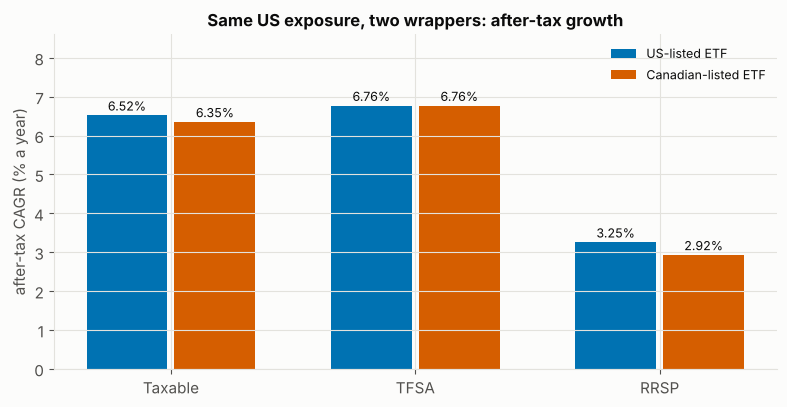

RRSP bars include the assumed 30% tax on the whole balance at withdrawal; compare the two wrappers inside one account.
Cost of the Canadian-listed wrapper (points of CAGR per year): {'Taxable': 0.17, 'TFSA': 0.0, 'RRSP': 0.33}


In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(3); w = 0.36
for k, n in enumerate(SPEC2):
    v = np.array([cagr(R2[(n, a)].after_tax_curve) for a in ACCOUNTS]) * 100
    bars = ax.bar(x + (k - .5) * w, v, w * 0.92, color=W_COL[n], label=NICE2[n])
    for b, y in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, y + 0.05, f"{y:.2f}%", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(x, [ACC_NAME[a] for a in ACCOUNTS]); ax.set_ylabel("after-tax CAGR (% a year)")
ax.set_ylim(0, 8.6); ax.set_title("Same US exposure, two wrappers: after-tax growth")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout(); display(fig); plt.close(fig)
print("RRSP bars include the assumed 30% tax on the whole balance at withdrawal; compare the two wrappers inside one account.")
gap = {a: (cagr(R2[("US_ETF", a)].after_tax_curve) - cagr(R2[("CA_ETF", a)].after_tax_curve)) * 100 for a in ACCOUNTS}
print("Cost of the Canadian-listed wrapper (points of CAGR per year):", {ACC_NAME[a]: round(float(g), 2) for a, g in gap.items()})

The bars only show the gap in growth; the stack below shows where it comes from, year by year, in dollars of withholding on a $100,000 start (the amounts grow with the account). Rows are the wrapper, columns the account. Orange is lost, light blue is credited back, green is exempt.

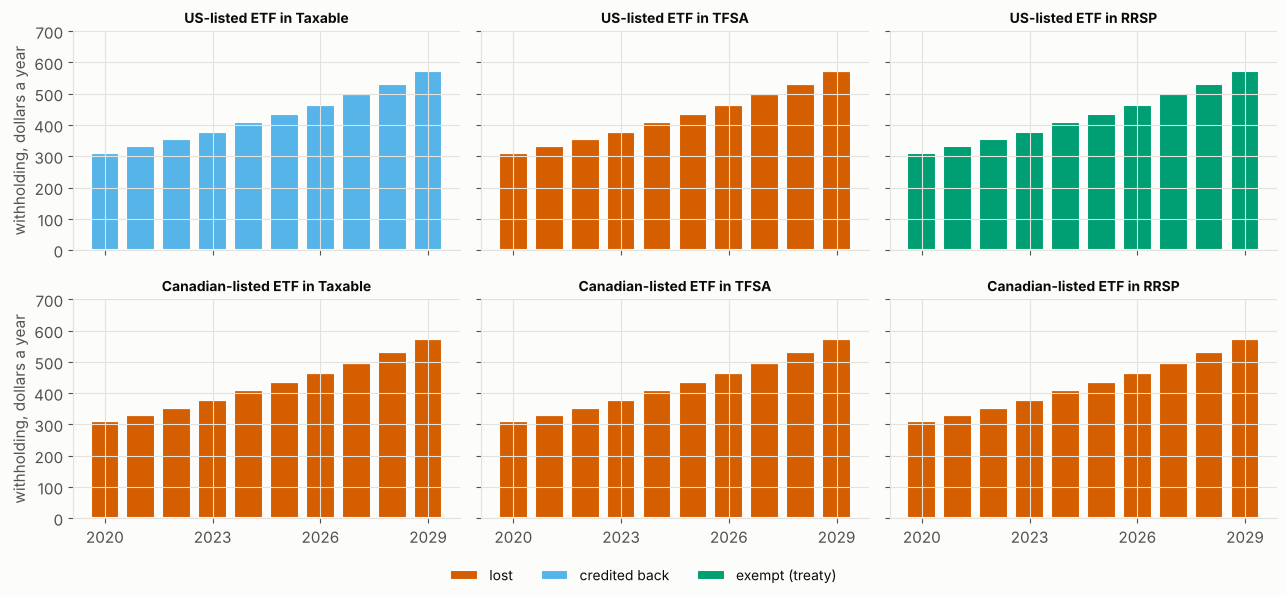

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True, sharex=True)
for i, n in enumerate(SPEC2):
    for j, a in enumerate(ACCOUNTS):
        ax = axes[i, j]; wh = withholding_dollars(R2[(n, a)], a)
        bottom = np.zeros(len(wh))
        for s in ("lost", "credited", "exempt"):
            ax.bar(wh.index, wh[s], 0.8, bottom=bottom, color=STATE_COL[s], label=s, edgecolor=SURFACE, linewidth=1.5)
            bottom += wh[s].to_numpy()
        ax.set_title(f"{NICE2[n]} in {ACC_NAME[a]}", fontsize=10)
        ax.set_xticks(wh.index[::3]); ax.set_ylim(0, 700)
        if j == 0: ax.set_ylabel("withholding, dollars a year")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h[:3], ["lost", "credited back", "exempt (treaty)"], loc="lower center", ncols=3, fontsize=10)
fig.tight_layout(rect=(0, 0.05, 1, 1)); display(fig); plt.close(fig)

**Reading it.** The Canadian-listed ETF loses the 15% in all three accounts: the bars are orange everywhere. The US-listed ETF loses it only in the TFSA, gets it back as a credit in the taxable account, and never pays it in the RRSP. So the wrapper matters most where you hold it: in an RRSP the US-listed ETF is clearly better, in a TFSA it is a tie, and in a taxable account it is better by the amount the credit returns. Currency conversion costs and fees on the two products are not modelled.

## 3. Currency and the cost base

Tax is computed in Canadian dollars. The adjusted cost base (ACB) of a US share is what you paid, converted at the exchange rate **on the day you bought**; the proceeds are converted at the rate **on the day you sold**. So a US-dollar gain can be a Canadian-dollar loss.

The test case: buy a US stock on 2020-01-01 with USDCAD at 1.40, sell on 2021-01-01. No dividends, so the currency is the only thing in play. (The stock is sold because the screen switches to a Canadian stock for 2021.)

* **Case A**: the US-dollar price rises **10%** and USDCAD falls **15%** (1.40 to 1.19).
* **Case B**, the reverse: the US-dollar price falls **5%** and USDCAD rises **15%** (1.40 to 1.61).

In [9]:
SPEC3 = {"US": dict(domicile="US", wrapper="stock", currency="USD"), "CAN": dict(domicile="CA", wrapper="stock", currency="CAD")}
D3 = pd.bdate_range("2020-01-01", "2021-12-31")
FX0 = 1.40

def case(usd_move, fx_move):
    """Price and FX move in a straight line over 2020 and the sale happens on 2021-01-01."""
    frac = np.clip((D3 - D3[0]).days.to_numpy() / (pd.Timestamp("2021-01-01") - D3[0]).days, 0, 1)
    usd = 1 + usd_move * frac
    fx = pd.Series(FX0 * (1 + fx_move * frac), index=D3)
    mk = make_market(SPEC3, years=2, yld=0.0, picks={"US": [2020], "CAN": [2021]}, prices=pd.DataFrame({"US": usd, "CAN": 1.0}, index=D3))
    macro = MacroSeries.from_frame(pd.DataFrame({"fx": fx}))
    tc = lambda m: TaxConfig(model=MODEL, account="taxable", capital=CAP, macro=m, pay_from_portfolio=False)
    sc = ScreenBuilder("pick", n=1).where("sector == 'US' or sector == 'CAN'").build()
    out = {}
    for key, m in (("cad", macro), ("usd", None)):
        out[key] = run(sc, mk, Config(rebalance_months=12, cost_bps=0, min_holdings=1, tax=tc(m)), start="2020-01-01").tax
    return pd.Series(usd, index=D3), fx, out

CASES = {"A": (0.10, -0.15), "B": (-0.05, 0.15)}
RES3 = {k: case(*v) for k, v in CASES.items()}

In [10]:
rows = []
for k, (usd_move, fx_move) in CASES.items():
    _, _, out = RES3[k]
    for label, key in (("USD view (no FX series loaded)", "usd"), ("CAD view (USDCAD loaded; what the CRA taxes)", "cad")):
        t = out[key].loc[2021]
        rows.append({"case": k, "USD price": f"{usd_move:+.0%}", "USDCAD": f"{fx_move:+.0%}", "view": label,
                     "realized gain ($)": t["realized_gains"], "realized loss ($)": t["realized_losses"],
                     "capital gains tax ($)": t["tax_capital_gains"]})
g = pd.DataFrame(rows).set_index(["case", "USD price", "USDCAD", "view"])
display(g.style.format("{:,.0f}"))
a_cad = RES3["A"][2]["cad"].loc[2021]; b_cad = RES3["B"][2]["cad"].loc[2021]
assert abs(a_cad["realized_losses"] - CAP * (1.10 * 0.85 - 1)) < 1e-6      # exact: 1.10 x 0.85 - 1 = -6.5%
assert abs(b_cad["realized_gains"] - CAP * (0.95 * 1.15 - 1)) < 1e-6       # exact: 0.95 x 1.15 - 1 = +9.25%
print(f"Case A: the US-dollar gain is +10%, the Canadian-dollar result is 1.10 x 0.85 - 1 = {1.10 * 0.85 - 1:+.2%}, "
      f"a loss of ${-a_cad['realized_losses']:,.0f} on $100,000, and no tax.")
print(f"Case B: the US-dollar result is -5%, the Canadian-dollar result is 0.95 x 1.15 - 1 = {0.95 * 1.15 - 1:+.2%}, "
      f"a gain of ${b_cad['realized_gains']:,.0f}, taxed: ${b_cad['tax_capital_gains']:,.0f}.")

Case A: the US-dollar gain is +10%, the Canadian-dollar result is 1.10 x 0.85 - 1 = -6.50%, a loss of $6,500 on $100,000, and no tax.
Case B: the US-dollar result is -5%, the Canadian-dollar result is 0.95 x 1.15 - 1 = +9.25%, a gain of $9,250, taxed: $1,411.


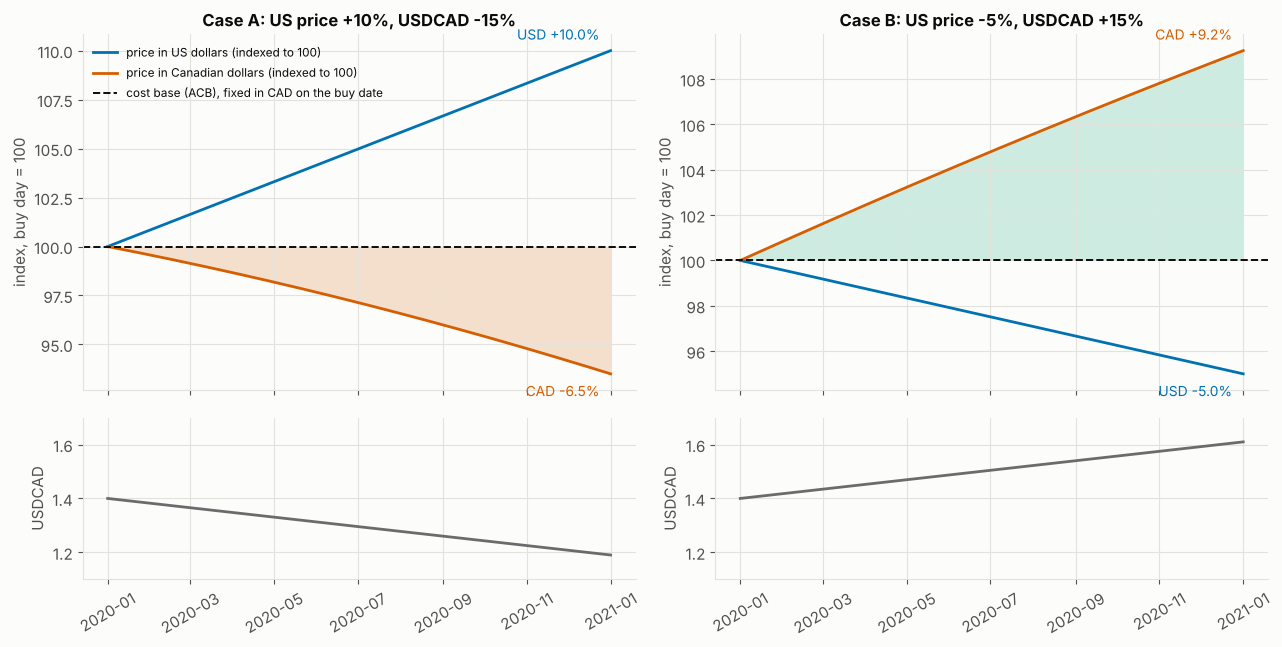

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6.6), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1]))
for j, (k, (usd_move, fx_move)) in enumerate(CASES.items()):
    usd, fx, out = RES3[k]
    sell = pd.Timestamp("2021-01-01"); keep = usd.index <= sell
    usd_i = 100 * usd[keep]; cad_i = 100 * usd[keep] * fx[keep] / FX0
    ax = axes[0, j]
    ax.plot(usd_i.index, usd_i, color="#0072B2", lw=2, label="price in US dollars (indexed to 100)")
    ax.plot(cad_i.index, cad_i, color="#D55E00", lw=2, label="price in Canadian dollars (indexed to 100)")
    ax.axhline(100, color=INK, lw=1.4, ls="--", label="cost base (ACB), fixed in CAD on the buy date")
    ax.fill_between(cad_i.index, 100, cad_i, where=cad_i >= 100, color="#009E73", alpha=0.18, lw=0)
    ax.fill_between(cad_i.index, 100, cad_i, where=cad_i < 100, color="#D55E00", alpha=0.18, lw=0)
    ax.annotate(f"USD {usd_i.iloc[-1] - 100:+.1f}%", (sell, usd_i.iloc[-1]), xytext=(-8, 8 if usd_i.iloc[-1] >= cad_i.iloc[-1] else -16),
                textcoords="offset points", ha="right", fontsize=10, color="#0072B2")
    ax.annotate(f"CAD {cad_i.iloc[-1] - 100:+.1f}%", (sell, cad_i.iloc[-1]), xytext=(-8, -16 if usd_i.iloc[-1] >= cad_i.iloc[-1] else 8),
                textcoords="offset points", ha="right", fontsize=10, color="#D55E00")
    ax.set_title(f"Case {k}: US price {usd_move:+.0%}, USDCAD {fx_move:+.0%}"); ax.set_ylabel("index, buy day = 100")
    if j == 0: ax.legend(loc="upper left", fontsize=8.5)
    axf = axes[1, j]; axf.plot(fx[keep].index, fx[keep], color=GREY, lw=2)
    axf.set_ylabel("USDCAD"); axf.set_ylim(1.1, 1.7); axf.tick_params(axis="x", rotation=30)
fig.tight_layout(); display(fig); plt.close(fig)

The top row has three lines: the price in US dollars (blue), the same price converted to Canadian dollars (vermillion), and the cost base (dashed). The shaded gap between the Canadian-dollar price and the cost base is what the CRA taxes (green) or lets you claim as a loss (red); the US-dollar line only matters through the exchange rate underneath. In Case A the blue line ends above 100 and the vermillion line ends below it: you were up in US dollars, down in Canadian dollars, and the tax return shows a **capital loss**. Case B is the reverse: your broker shows a loss, but there is a taxable gain.

If **no exchange-rate series is loaded**, the tax stage cannot convert, taxes the US-dollar numbers as if they were Canadian, and says so:

In [12]:
for k in CASES:
    w = RES3[k][2]["usd"].attrs["warnings"]
    print(f"Case {k}, no FX series -> warning: {FX_WARNING}")
    assert FX_WARNING in w and FX_WARNING not in RES3[k][2]["cad"].attrs["warnings"]

Case A, no FX series -> warning: foreign gains taxed in portfolio currency; load an FX series for CAD basis
Case B, no FX series -> warning: foreign gains taxed in portfolio currency; load an FX series for CAD basis


In the table above, the "USD view" rows are what you would get without the series (a gain in Case A that is not real; a loss in Case B that hides a real gain). The series needs to be **USDCAD** (Canadian dollars per US dollar, `MacroSeries` column `fx`); it converts gains and the dividends of names whose `currency` is USD.

## 4. Real data pointer: the bundled S&P 500 sample

The bundled sample has 20 large US companies (1990-2022, prices only, in US dollars). As in `accounts_and_foreign.ipynb`, an **assumed 2% yield** is added so that dividends exist for the tax stage to withhold on; the 2% is an assumption, not data. Every name is US, so the foreign treatment is the "US stock, direct" row of the matrix in Section 1. No FX series is loaded here, so the gains are taxed in US dollars as if Canadian; the comparison says so in its notes (printed under the data card).

In [13]:
from screenlab import Lab
from screenlab.benchmarks import IndexBenchmark
from screenlab.dataset import BundledSP500Builder
from screenlab.realdata import bundled

ds = BundledSP500Builder().build()
q = ds.prices.resample("QE").last().dropna(how="all")
rows = [dict(date=d, ticker=t, price=p, sector=bundled.SECTORS[t], market_cap=np.nan, dividend=0.02 * p)
        for d, r in q.iterrows() for t, p in r.dropna().items()]
ds2 = Dataset.from_frames(add_ratios(pd.DataFrame(rows)), ds.prices, ds.indices, name="sp500_bundled+2%div",
                          source="skfolio sample + assumed 2% yield", index_kinds={"SP500": "price"}, pit=None,
                          currency="USD", security_meta=ds.security_meta)
sp = Lab.from_dataset(ds2, screens=bundled.price_screens(5), benchmark=IndexBenchmark("SP500", dividend_yield=0.02))
TAX = TaxConfig(model=MODEL, account="taxable", rrsp_withdrawal_rate=0.30)
rep = sp.account_compare(["momentum_12_1"], tax=TAX, rebalance_months=12)
print(rep.data_card.line()); print(rep.data_card.foreign_line())
print([n for n in rep.notes if n.startswith('CAD-basis')])
cols = ["name", "account", "CAGR", "AfterTaxCAGR", "TaxDrag/yr", "WHLost/yr", "WHCredited/yr", "WHExempt/yr", "TaxPaid$"]
display(rep.table[cols].set_index(["name", "account"]).style.format(
    {"CAGR": "{:.2%}", "AfterTaxCAGR": "{:.2%}", "TaxDrag/yr": "{:.2%}", "WHLost/yr": "{:.2%}", "WHCredited/yr": "{:.2%}",
     "WHExempt/yr": "{:.2%}", "TaxPaid$": "{:,.0f}"}))

Data: sp500_bundled+2%div, 1990-01-02..2022-12-28, 20 names, benchmark SP500 (approx_total_return: price index + assumed 2.0%/yr dividends), PIT n/a, delisted no, survivorship +7.9%/yr
foreign: 100% of names (US 100%), currencies USD; withholding: taxable creditable (FTC), tfsa lost, rrsp exempt (US-listed); Canadian ETF on foreign stocks: lost in every account
foreign: 100% of names (US 100%), currencies USD; withholding: taxable creditable (FTC), tfsa lost, rrsp exempt (US-listed); Canadian ETF on foreign stocks: lost in every account
['CAD-basis warning: foreign gains taxed in portfolio currency; load an FX series for CAD basis']


(the shared module is present; this notebook still draws the three-panel version it needs)


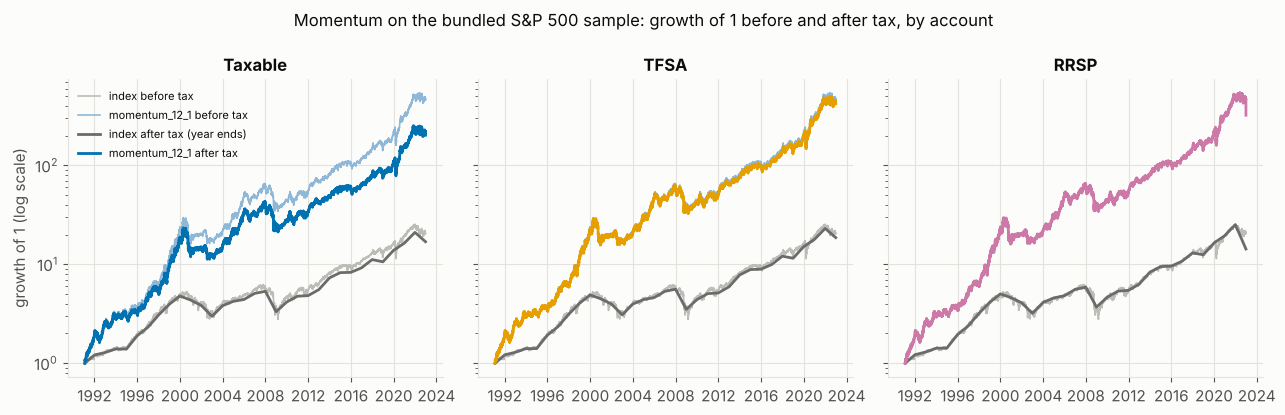

In [14]:
def draw_after_tax_curves(rep, name, axes):
    """After-tax growth of $1, one panel per account: the portfolio's curve and the equally taxed index (year-end points)."""
    for ax, a in zip(axes, ACCOUNTS):
        r = rep.reports[a]; res = r.results[name]
        ax.plot(r.benchmark.index, r.benchmark / r.benchmark.iloc[0], color="#BDBCB7", lw=1.2, label="index before tax")
        ax.plot(res.curve.index, res.curve / res.curve.iloc[0], color="#8FB8D8", lw=1.2, label=f"{name} before tax")
        ix = r.tax[rep.benchmark]["wealth_after_tax"] / CAP
        ye = pd.Series(ix.to_numpy(), index=[res.after_tax_curve[res.after_tax_curve.index.year == y].index[-1] for y in ix.index])
        ye = pd.concat([pd.Series([1.0], index=[res.after_tax_curve.index[0]]), ye])
        ax.plot(ye.index, ye, color=GREY, lw=2, label="index after tax (year ends)")
        ax.plot(res.after_tax_curve.index, res.after_tax_curve, color=ACC_COL[a], lw=2, label=f"{name} after tax")
        ax.set_yscale("log"); ax.set_title(ACC_NAME[a]); ax.set_ylabel("growth of 1 (log scale)" if a == "taxable" else "")
    axes[0].legend(fontsize=8, loc="upper left")

if tax_plots is not None and hasattr(tax_plots, "after_tax_curves"):
    print("(the shared module is present; this notebook still draws the three-panel version it needs)")
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
draw_after_tax_curves(rep, "momentum_12_1", axes)
fig.suptitle("Momentum on the bundled S&P 500 sample: growth of 1 before and after tax, by account", fontsize=12)
fig.tight_layout(); display(fig); plt.close(fig)

In the TFSA the after-tax line sits just under the before-tax line (only the 15% withholding is lost), in the RRSP it sits under it by the same amount until the last day, when the assumed 30% withdrawal tax pulls it down, and in the taxable account it falls behind steadily as dividends and sales are taxed.

**With your own data.** Load a total-return series for the names you hold (or a screen-ready `fundamentals.csv` with dividends) and add a `securities.csv` next to it with one row per ticker and the columns `ticker, domicile, wrapper, currency, underlying_domicile` (blank cells get the defaults: Canada, CAD, `stock`). Set `wrapper` to `etf_ca` and `underlying_domicile` to `US` for a Canadian-listed US ETF, `etf_us` for a US-listed one. Then the data card shows `foreign: ...` and the matrix from Section 1 is applied to *your* names rather than to an assumed 2% yield. For USD names, load a USDCAD series as a macro `fx` column and pass it as `TaxConfig(macro=...)`; otherwise Section 3's warning applies.

## 5. How to read this, and what it ignores

**What it tells you**

* Withholding is not one cost: the same 15% is *lost*, *credited* or *exempt* depending on the account and the wrapper (Section 1). Where a holding lives can matter as much as which holding it is.
* A Canadian-listed ETF on US stocks pays the withholding inside the fund in every account (Section 2). A US-listed ETF avoids it in an RRSP and recovers it in a taxable account.
* Your gain is a Canadian-dollar gain: a US-dollar gain can be a loss, and a US-dollar loss a taxable gain, because the cost base is fixed at the buy-day exchange rate (Section 3).

**What it ignores**

* **Only USD is converted.** The tax stage reads one FX series, `fx_currency="USD"`. Names in other currencies (GBP, EUR) are not converted; their withholding rate is by country, but their gains are not put on a CAD basis.
* **Fund NAV already net of withholding.** If the total-return series you load for an ETF is the fund's own NAV, the fund's internal withholding is already in it, and the tax stage then takes it a second time. Use a gross-of-withholding series, or accept a small double count.
* **Forms and special rules:** T1135 (foreign property over $100,000 CAD held outside registered accounts), estate-tax exposure on US securities above the US exemption, PFIC treatment of foreign funds, and the foreign tax credit limits beyond the simple approximation (the credit is capped at the Canadian tax on that income).
* **Trading costs of converting currency**, fund fees, and the interest on cash balances in USD.
* **Contribution room**, the RRSP deduction refund, and AMT, as in the accounts notebook.
* Taxes are Alberta 2025 for a $90,000 salary; the hand-made markets are made up and flat on purpose. Numbers show the mechanics, they are not a forecast and not tax advice.